In [ ]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split
from IPython.display import display
from sklearn.metrics import mutual_info_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression




%matplotlib inline


# Document data source and retrieval steps.

In [ ]:
# data is available in the data folder, original dataset retreived from https://www.kaggle.com/datasets/joniarroba/noshowappointments/data
df = pd.read_csv("data/KaggleV2-May-2016.csv")

# Data preparation and data cleaning

In [ ]:
print("head")
print(df.head())

summary = pd.DataFrame({
    "count": df.count(),
    "type": df.dtypes
})

print(summary)

head
      PatientId  AppointmentID Gender          ScheduledDay  \
0  2.987250e+13        5642903      F  2016-04-29T18:38:08Z   
1  5.589978e+14        5642503      M  2016-04-29T16:08:27Z   
2  4.262962e+12        5642549      F  2016-04-29T16:19:04Z   
3  8.679512e+11        5642828      F  2016-04-29T17:29:31Z   
4  8.841186e+12        5642494      F  2016-04-29T16:07:23Z   

         AppointmentDay  Age      Neighbourhood  Scholarship  Hipertension  \
0  2016-04-29T00:00:00Z   62    JARDIM DA PENHA            0             1   
1  2016-04-29T00:00:00Z   56    JARDIM DA PENHA            0             0   
2  2016-04-29T00:00:00Z   62      MATA DA PRAIA            0             0   
3  2016-04-29T00:00:00Z    8  PONTAL DE CAMBURI            0             0   
4  2016-04-29T00:00:00Z   56    JARDIM DA PENHA            0             1   

   Diabetes  Alcoholism  Handcap  SMS_received No-show  
0         0           0        0             0      No  
1         0           0        0 

Not all columns are named consistently so we will rename them

In [ ]:
df.columns = df.columns.str.lower().str.replace(' ', '_')
df.columns = df.columns.str.lower().str.replace('-', '_')

No-show is a string with Yes and No so we will convert it to intergers 1 and 0 for ease of use. 


In [ ]:
df["no_show_int"] = (df["no_show"] == "Yes").astype(int)

We have the dates of the appointment and when it was scheduled in appointmentday and scheduledday respectively. From those dates we can calculate how longago an appointment was made, which might have an influence on the no_show value. 

In [ ]:
df["appointmentday"] = pd.to_datetime(df["appointmentday"])
df["scheduledday"] = pd.to_datetime(df["scheduledday"])

# as scheduledday does not have hours we make sure we only use the date and not the hours. 
df["wait_time"] = (df["appointmentday"].dt.normalize() - df["scheduledday"].dt.normalize()).dt.days
print("Minimum:", df["wait_time"].min())
print("Maximum:", df["wait_time"].max())

Minimum: -6
Maximum: 179


There are days where the scheduledday are before the appointment days. Lets see how often this happens and remove those rows as they cannot be valid

In [ ]:
df["wait_time"].value_counts().sort_index()


wait_time
-6          1
-1          4
 0      38563
 1       5213
 2       6725
        ...  
 155       10
 162       11
 169        8
 176       16
 179       10
Name: count, Length: 131, dtype: int64

there are 4 rows where the scheduledday was 1 day after the appointment day and 1 row where it was 6 days before. 

In [ ]:
df = df[df["wait_time"] >= 0]


Lets set up some standard lists so we can use them later

In [ ]:
categorical = [
    'gender',
    'age_group',
    'sms_received',
    'hipertension',
    'diabetes',
    'alcoholism',
    'handcap',
    'scholarship',
    'neighbourhood'
]

numerical = [
    'age',
    'wait_time'
]


# Explore distributions, missing values, correlations, outliers.

In [ ]:
## missing values:
df.isnull().sum()

patientid         0
appointmentid     0
gender            0
scheduledday      0
appointmentday    0
age               0
neighbourhood     0
scholarship       0
hipertension      0
diabetes          0
alcoholism        0
handcap           0
sms_received      0
no_show           0
no_show_int       0
wait_time         0
dtype: int64

Check the descriptive statistics of the dataset

In [ ]:
df.describe()


,patientid,appointmentid,age,scholarship,hipertension,diabetes,alcoholism,handcap,sms_received,no_show_int,wait_time
count,1.105220e+05,1.105220e+05,110522.000000,110522.000000,110522.000000,110522.000000,110522.000000,110522.000000,110522.000000,110522.000000,110522.000000
mean,1.474935e+14,5.675305e+06,37.089041,0.098270,0.197255,0.071868,0.030401,0.022231,0.321040,0.201896,10.184253
std,2.560866e+14,7.129722e+04,23.110064,0.297681,0.397928,0.258270,0.171689,0.161493,0.466878,0.401417,15.255115
min,3.921784e+04,5.030230e+06,-1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,4.172536e+12,5.640284e+06,18.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,3.173700e+13,5.680574e+06,37.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000
75%,9.439277e+13,5.725525e+06,55.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,15.000000
max,9.999816e+14,5.790484e+06,115.000000,1.000000,1.000000,1.000000,1.000000,4.000000,1.000000,1.000000,179.000000


Age has at least 1 negative number which will have to be removed. Age also has a maximum of 115 which seems a bit high, lets take a look if there is an outlier which we are better of removing.


handcap has a min value of 0 and a max of 4 which might indicate severity and is not just 0 and 1 for a yes/no. however the quartiles give an indication that there are either very little values of 1 to 4 or that there is an error in the data. 

In [ ]:
df = df[df["age"] >= 0]
df.loc[df["age"] > 80, "age"].value_counts().sort_index()


age
81     433
82     392
83     280
84     311
85     275
86     260
87     184
88     126
89     173
90     109
91      66
92      86
93      53
94      33
95      24
96      17
97      11
98       6
99       1
100      4
102      2
115      5
Name: count, dtype: int64

5 subjects with an age of 115 and none between 102 and 115 seems off, i will be removing those rows as they do not seem reliable. 

In [ ]:
df = df[df["age"] < 115]


Handcap had quantiles of all zeros and a maximum of 4, lets quickly check if there is an issue with the data or if the counts are just very low. 

In [ ]:
df["handcap"].value_counts().sort_index()

handcap
0    108281
1      2036
2       183
3        13
4         3
Name: count, dtype: int64

The counts for handcap seem to just be very low. 

## Distributions
main the feature that we will predict is the 'No-show' column
We will thus first look at the distribution of this feature itself and how it relates to other features. 

### No-show

Text(0.5, 1.0, 'No Show distribution')

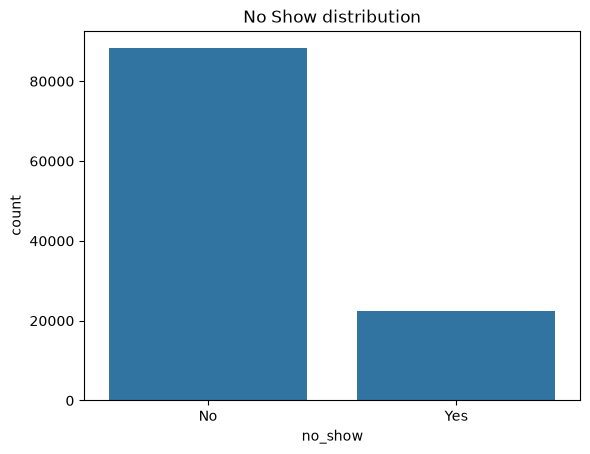

In [ ]:
sns.countplot(df, x = "no_show")
plt.title("No Show distribution")

In [ ]:
# Percentage of No-show:
df["no_show"].value_counts(normalize = True).round(4)*100


no_show
No     79.81
Yes    20.19
Name: proportion, dtype: float64

### Age

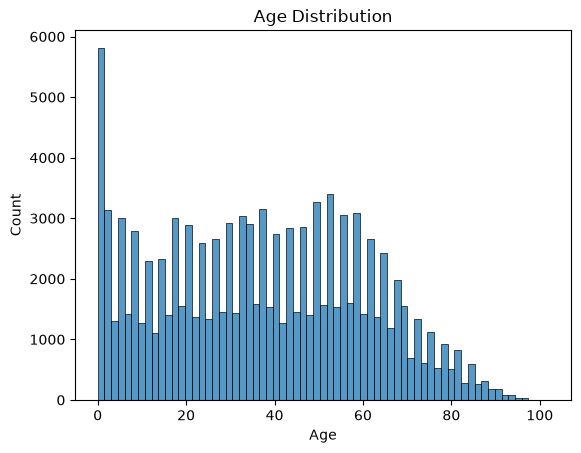

In [ ]:
# Distribution of Age
age_hist = sns.histplot(df.age)
age_hist.plot(
    kind="hist",
    stacked=True,
    figsize=(10, 6)
)

plt.xlabel("Age")
plt.ylabel("Count")
plt.title("Age Distribution")
plt.show()

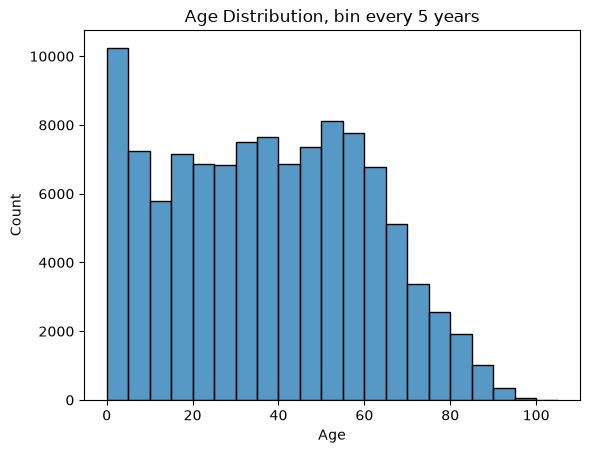

In [ ]:
age_hist = sns.histplot(df.age, bins=range(0, int(df["age"].max()) + 6, 5))
age_hist.plot(
    kind="hist",
    stacked=True,
    figsize=(10, 6)
)

plt.xlabel("Age")
plt.ylabel("Count")
plt.title("Age Distribution, bin every 5 years")
plt.show()

As there is a clear dropoff after 65+ which might make the prediction on higher age less reliable. I will make an age_group variable cutting off after 70 to maybe use this later to increase the reliablitlity for older subjects. 


In [ ]:
df["age_group"] = pd.cut(
    df["age"],
    bins=list(range(0, 71, 5)) + [df["age"].max() + 1],
    right=False
).astype(str)

# check the percentages if these groups are relatively equal
df["age_group"].value_counts(normalize = True).round(4)*100

age_group
[0, 5)       9.27
[70, 103)    8.41
[50, 55)     7.34
[55, 60)     7.02
[35, 40)     6.93
[30, 35)     6.80
[45, 50)     6.66
[5, 10)      6.54
[15, 20)     6.47
[20, 25)     6.20
[40, 45)     6.20
[25, 30)     6.19
[60, 65)     6.13
[10, 15)     5.23
[65, 70)     4.62
Name: proportion, dtype: float64

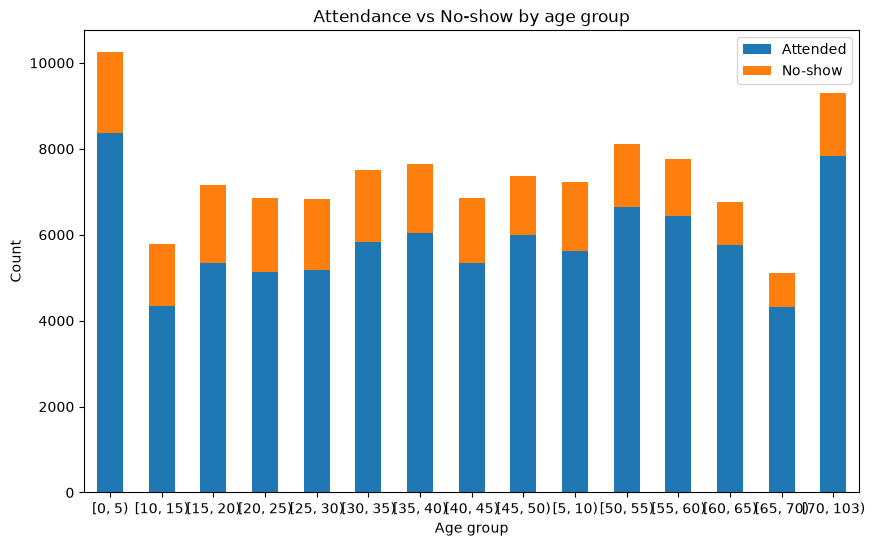

In [ ]:
age_counts = pd.crosstab(
    df["age_group"],
    df["no_show_int"]
)

age_counts.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.xlabel("Age group")
plt.ylabel("Count")
plt.title("Attendance vs No-show by age group")
plt.legend(["Attended", "No-show"])
plt.xticks(rotation=0)
plt.show()


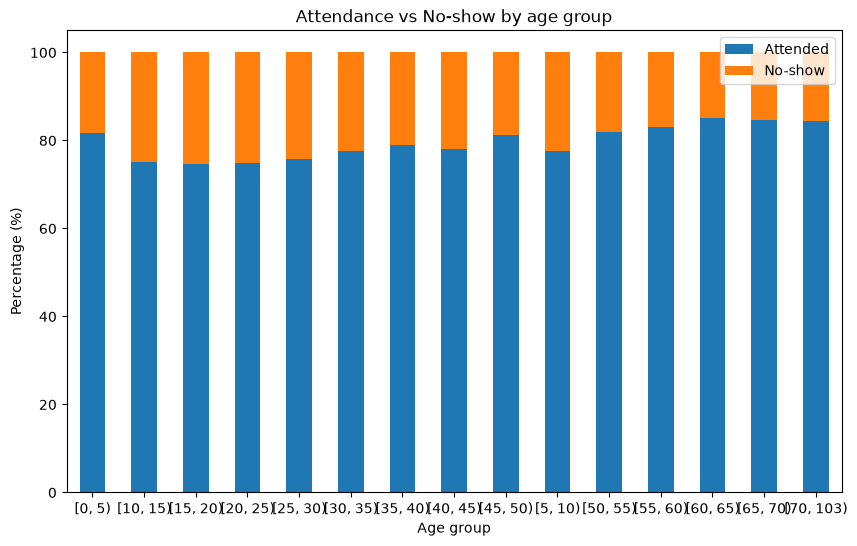

In [ ]:
age_rate = pd.crosstab(
    df["age_group"],
    df["no_show_int"],
    normalize="index"
) * 100

age_rate.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.xlabel("Age group")
plt.ylabel("Percentage (%)")
plt.title("Attendance vs No-show by age group")
plt.legend(["Attended", "No-show"])
plt.xticks(rotation=0)
plt.show()

In [ ]:
df.groupby("age_group")["no_show_int"].mean().mul(100)

age_group
[0, 5)       18.209334
[10, 15)     24.939467
[15, 20)     25.359989
[20, 25)     25.149526
[25, 30)     24.185299
[30, 35)     22.488357
[35, 40)     21.018942
[40, 45)     21.982192
[45, 50)     18.673553
[5, 10)      22.372788
[50, 55)     17.984458
[55, 60)     16.993296
[60, 65)     14.901787
[65, 70)     15.298727
[70, 103)    15.584975
Name: no_show_int, dtype: float64

Age groups are relatively equally represented in the attendance records. however it does seem like we could interpret a slight increase in attendance the older a person is. With the exception of 0 to 10, which could be caused by them being dependant on their parents/guardians. 


### Gender

Check how Gender is distributed including compared to age and no-show status

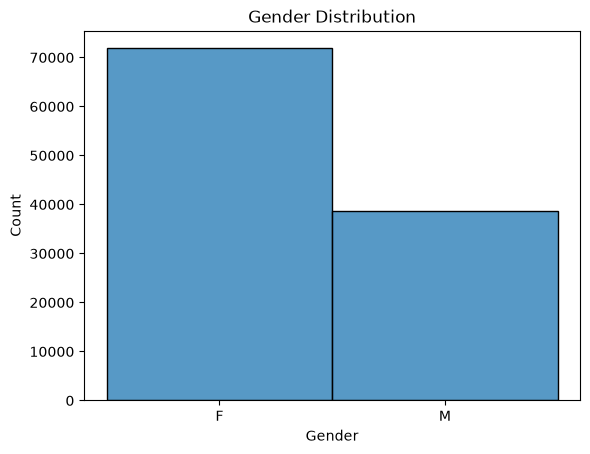

In [ ]:
# Distribution of Gender
gender_hist = sns.histplot(df.gender)

plt.xlabel("Gender")
plt.ylabel("Count")
plt.title("Gender Distribution")
plt.show()

In [ ]:
df["gender"].value_counts(normalize=True).mul(100)

gender
F    64.996019
M    35.003981
Name: proportion, dtype: float64

almost 2/3rd of the population is female. lets now look at the No-show rate amongst the genders.

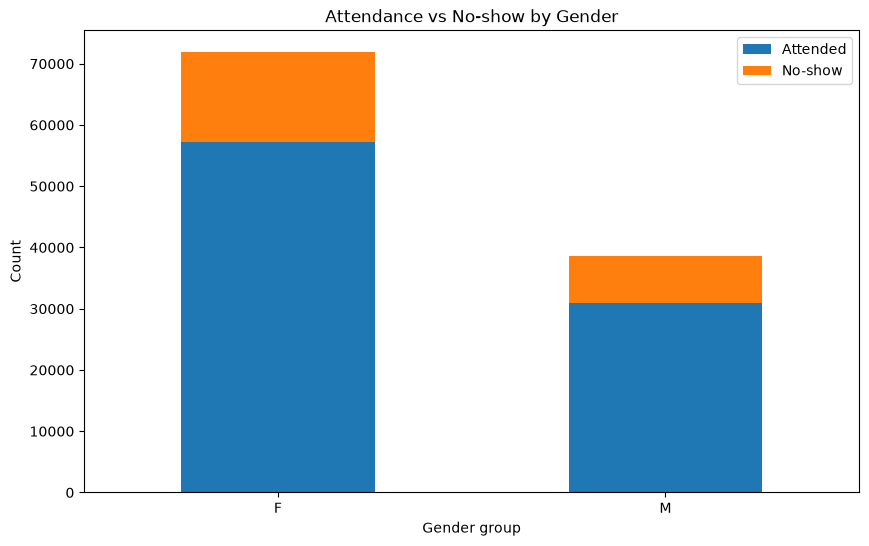

In [ ]:
gender_counts = pd.crosstab(
    df["gender"],
    df["no_show_int"]
)

gender_counts.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.xlabel("Gender group")
plt.ylabel("Count")
plt.title("Attendance vs No-show by Gender")
plt.legend(["Attended", "No-show"])
plt.xticks(rotation=0)
plt.show()

In [ ]:
df.groupby("gender")["no_show_int"].mean().mul(100)

gender
F    20.30878
M    19.96381
Name: no_show_int, dtype: float64

The distribution of no-show between males and females is relatively equal. Telling us that gender alone is not a perfect predictor of attendance. 

## SMS Received

What is the distribution of receiving a notification and can it be related to the attendance. 

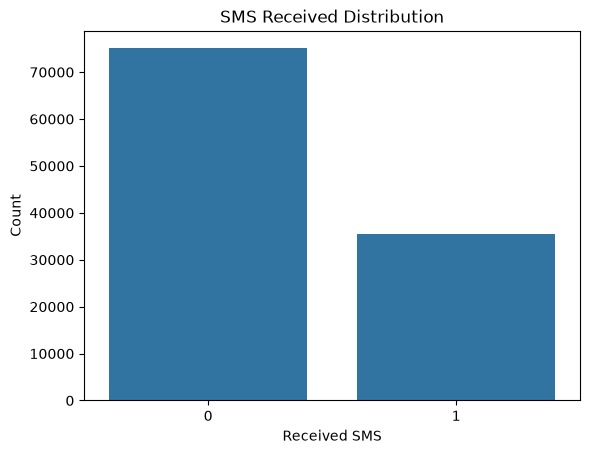

In [ ]:
# Distribution of sms_received
sms_hist = sns.countplot(data = df, x = "sms_received")

plt.xlabel("Received SMS")
plt.ylabel("Count")
plt.title("SMS Received Distribution")
plt.show()

In [ ]:
df["sms_received"].value_counts(normalize=True).mul(100)

sms_received
0    67.895146
1    32.104854
Name: proportion, dtype: float64

Just like the gender the split is around 2/3 to 1/3. Lets again look at the no-show rates between them.

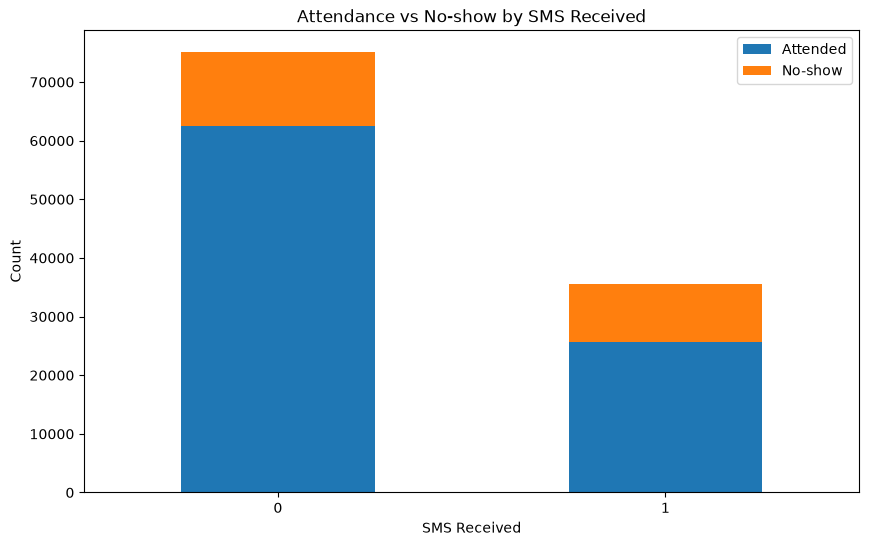

In [ ]:
sms_counts = pd.crosstab(
    df["sms_received"],
    df["no_show_int"]
)

sms_counts.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.xlabel("SMS Received")
plt.ylabel("Count")
plt.title("Attendance vs No-show by SMS Received")
plt.legend(["Attended", "No-show"])
plt.xticks(rotation=0)
plt.show()

In [ ]:
df.groupby("sms_received")["no_show_int"].mean().mul(100)

sms_received
0    16.694876
1    27.575322
Name: no_show_int, dtype: float64

Interestingly it seems like patients who received the SMS have a higher no-show rate. 

As i suspect the chance of younger patients having set up the SMS reminder is higher than older patients i will now take quick look if this could be a partial cause of the difference

In [ ]:
df.groupby("age_group")["sms_received"].mean().mul(100)

age_group
[0, 5)       25.785979
[10, 15)     31.649948
[15, 20)     29.819656
[20, 25)     35.361050
[25, 30)     34.268596
[30, 35)     34.171657
[35, 40)     32.971914
[40, 45)     33.673916
[45, 50)     31.992389
[5, 10)      32.674226
[50, 55)     34.168003
[55, 60)     33.393502
[60, 65)     32.860730
[65, 70)     34.142997
[70, 103)    28.672909
Name: sms_received, dtype: float64

It seems like my suspicion was incorrect and the SMS received i relatively eual between groups 20 to 70, only dropping 4 percent in the other groups. 

### Length of time between appointment and time of scheduling (wait_time)

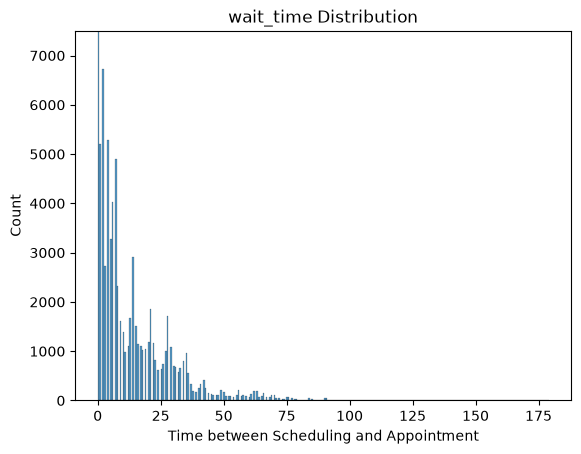

In [ ]:
# Distribution of wait_time
wait_time_hist = sns.histplot(df.wait_time)
wait_time_hist.plot(
    kind="hist",
    stacked=True,
    figsize=(10, 6)
)

plt.xlabel("Time between Scheduling and Appointment")
plt.ylabel("Count")
plt.title("wait_time Distribution")
plt.ylim(0, 7500) # as 0 days has a count of almost 40.000 we cut it of here to see the distribution better
plt.show()

amount of appointments scheduled more than 2 months seems very low. Lets take a look at the amount over 61 days. 

Text(0.5, 1.0, 'wait_time over 61 Distribution')

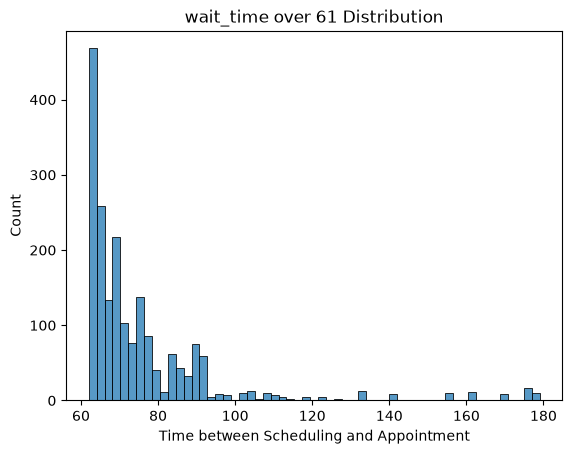

In [ ]:
df.loc[df["wait_time"] > 61, "wait_time"].value_counts().sort_index()
# Distribution of wait_time
wait_time_hist = sns.histplot(df.loc[df["wait_time"] > 61, "wait_time"])
wait_time_hist.plot(
    kind="hist",
    stacked=True,
    figsize=(10, 6)
)

plt.xlabel("Time between Scheduling and Appointment")
plt.ylabel("Count")
plt.title("wait_time over 61 Distribution")

Results does not seem unreasonable as some appointments might just be scheduled far in the future. from the max value of 179 days we saw earlier it is around 6 months so that seems reasonable to me. 

Next lets look at the behaviour of no-show over the waiting time. 

First we will do a scatterplot to see if the percentage of patients who no-show increases or decreases over a longer waiting time. 

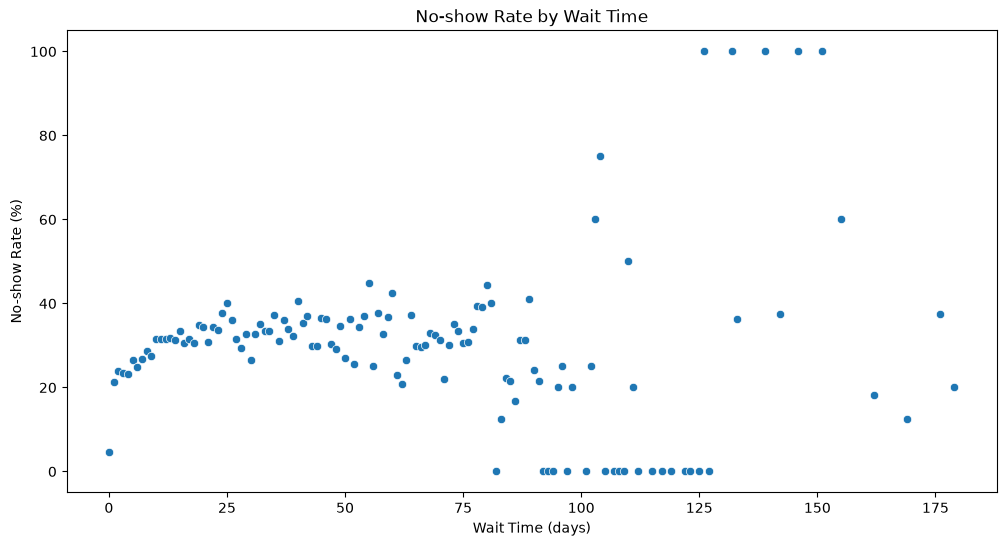

In [ ]:
# Calculate no-show rate per wait_time
wait_time_rate = (
    df.groupby("wait_time")["no_show_int"]
    .mean()
    .mul(100)
    .reset_index(name="no_show_rate")
)

# Plot
plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=wait_time_rate,
    x="wait_time",
    y="no_show_rate"
)

plt.xlabel("Wait Time (days)")
plt.ylabel("No-show Rate (%)")
plt.title("No-show Rate by Wait Time")

plt.show()

Conclusion for this figure seems that the no-show rate seems to be relatively stable over the wait time, hoever the longer the wait the less data we have so the scatterplot goes up and down allot. 

We can also make a box plot to check the distribution of the wait time among subjects who no-showed vs subjects that attended. 

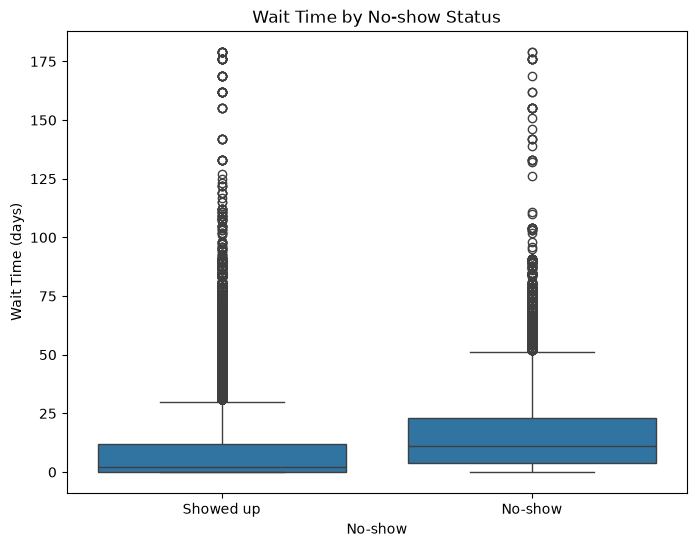

In [ ]:
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df,
    x="no_show",
    y="wait_time"
)

plt.xlabel("No-show")
plt.ylabel("Wait Time (days)")
plt.title("Wait Time by No-show Status")

plt.xticks([0, 1], ["Showed up", "No-show"])

plt.show()

Conclustion subjects that were No-shows generally had a longer waiting time than people who did show up. 

I can imagine that this is influenced by the large amount of subjects with 0 days. Lets remove those from this boxplot and check again. 

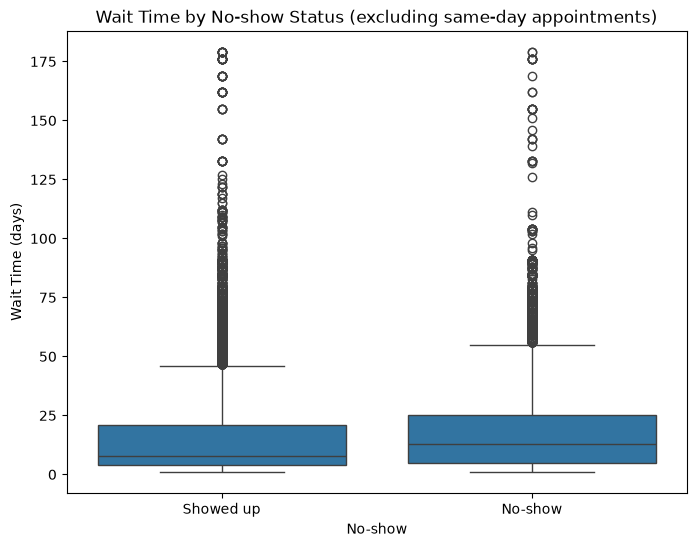

In [ ]:
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df[df["wait_time"] > 0],
    x="no_show",
    y="wait_time"
)

plt.xlabel("No-show")
plt.ylabel("Wait Time (days)")
plt.title("Wait Time by No-show Status (excluding same-day appointments)")

plt.xticks([0, 1], ["Showed up", "No-show"])

plt.show()


The difference is less stark between the two groups but is still present, i think this wait time could be a good predictor. 

### general health 
for each of the 4 health categories do a quick check if there is anything that grabs the attention. 
todo: overview of hipertension, diabetes, alcoholism, handcap .

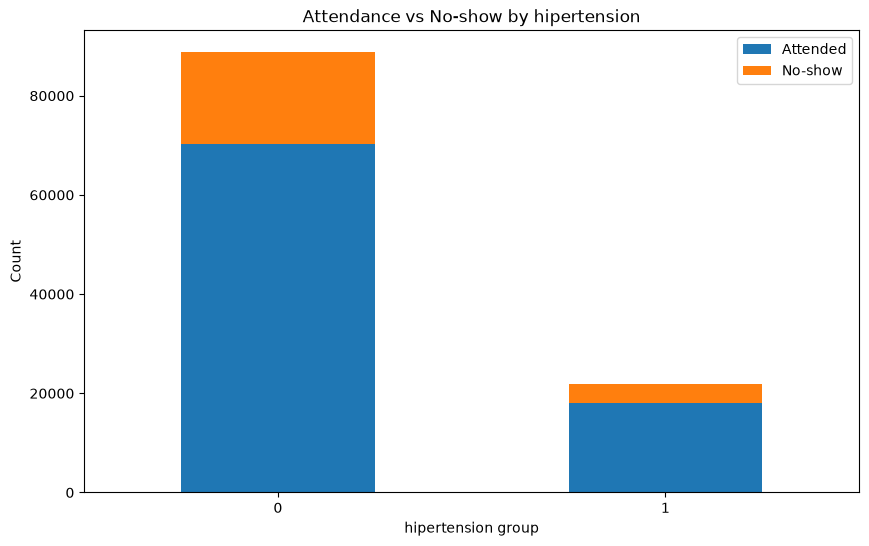

In [ ]:
hipertension_counts = pd.crosstab(
    df["hipertension"],
    df["no_show_int"]
)

hipertension_counts.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.xlabel("hipertension group")
plt.ylabel("Count")
plt.title("Attendance vs No-show by hipertension")
plt.legend(["Attended", "No-show"])
plt.xticks(rotation=0)
plt.show()

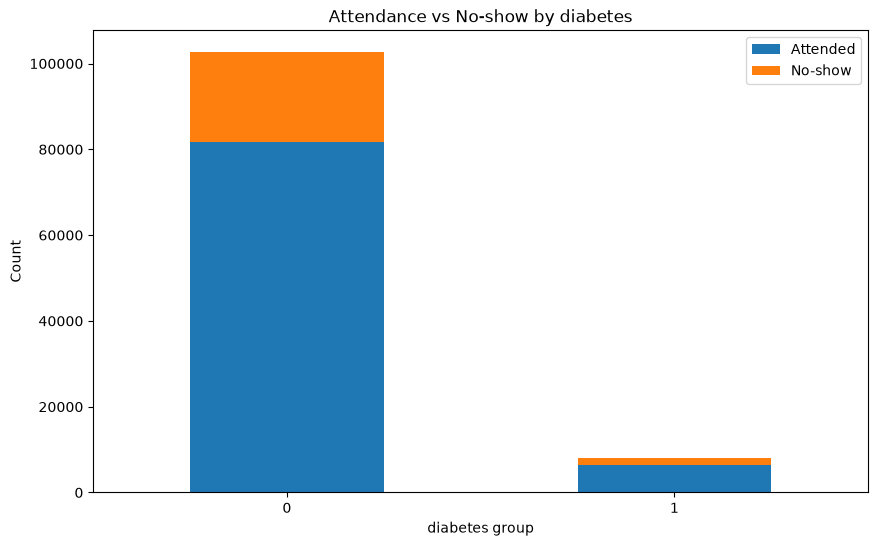

In [ ]:
diabetes_counts = pd.crosstab(
    df["diabetes"],
    df["no_show_int"]
)

diabetes_counts.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.xlabel("diabetes group")
plt.ylabel("Count")
plt.title("Attendance vs No-show by diabetes")
plt.legend(["Attended", "No-show"])
plt.xticks(rotation=0)
plt.show()

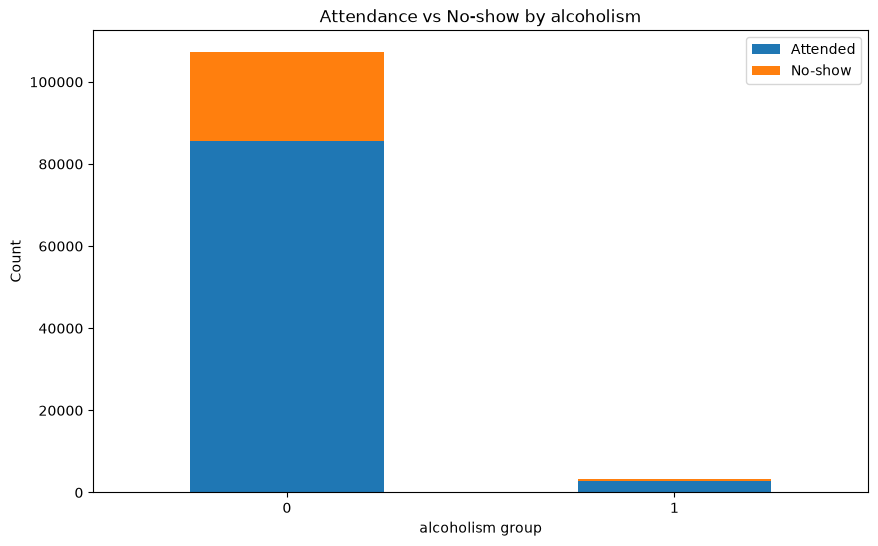

In [ ]:
alcoholism_counts = pd.crosstab(
    df["alcoholism"],
    df["no_show_int"]
)

alcoholism_counts.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.xlabel("alcoholism group")
plt.ylabel("Count")
plt.title("Attendance vs No-show by alcoholism")
plt.legend(["Attended", "No-show"])
plt.xticks(rotation=0)
plt.show()

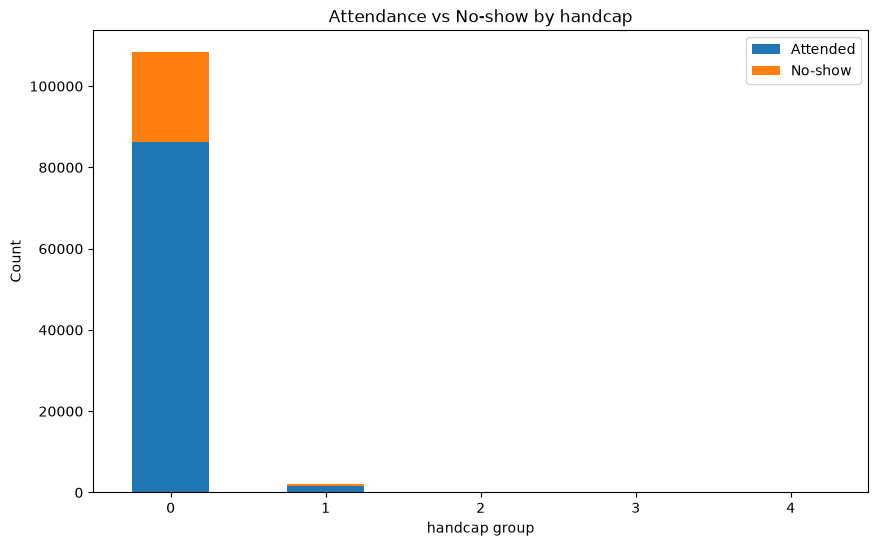

In [ ]:
handcap_counts = pd.crosstab(
    df["handcap"],
    df["no_show_int"]
)

handcap_counts.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.xlabel("handcap group")
plt.ylabel("Count")
plt.title("Attendance vs No-show by handcap")
plt.legend(["Attended", "No-show"])
plt.xticks(rotation=0)
plt.show()

Has this is hard to see for the smaller values we will normalize it to percentages

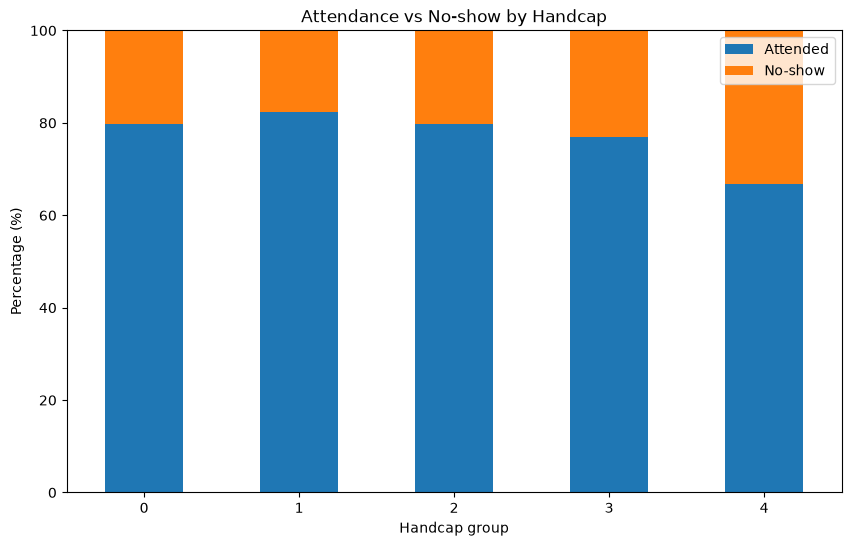

In [ ]:
handcap_percent = pd.crosstab(
    df["handcap"],
    df["no_show_int"],
    normalize="index"
) * 100

handcap_percent.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.xlabel("Handcap group")
plt.ylabel("Percentage (%)")
plt.title("Attendance vs No-show by Handcap")
plt.legend(["Attended", "No-show"])
plt.xticks(rotation=0)
plt.ylim(0, 100)

plt.show()

No category seems to be overrepresented for no-show. 

### neighbourhood



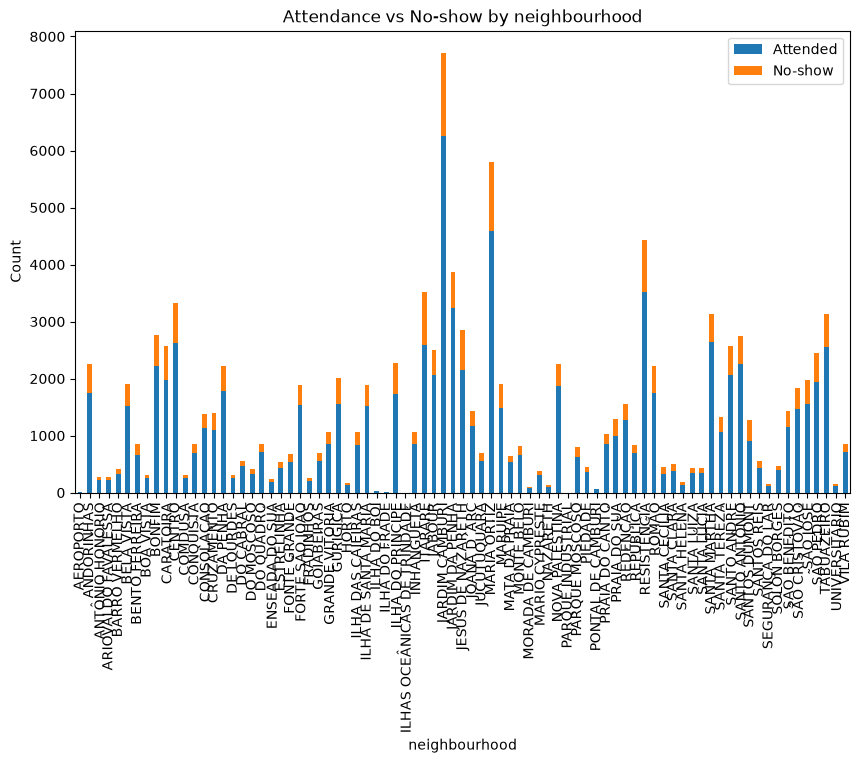

In [ ]:
neighbourhood_counts = pd.crosstab(
    df["neighbourhood"],
    df["no_show_int"]
)

neighbourhood_counts.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.xlabel("neighbourhood")
plt.ylabel("Count")
plt.title("Attendance vs No-show by neighbourhood")
plt.legend(["Attended", "No-show"])
plt.xticks(rotation=90)
plt.show()

Just the count does not really a good view of any neighbourhood stands out one way or another. 

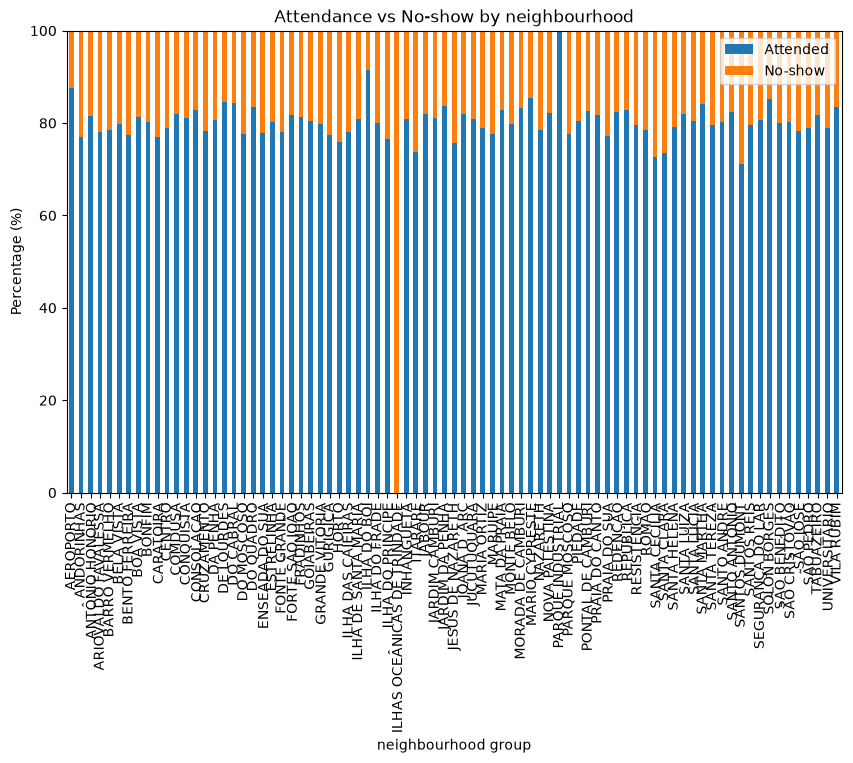

In [ ]:
neighbourhood_percent = pd.crosstab(
    df["neighbourhood"],
    df["no_show_int"],
    normalize="index"
) * 100

neighbourhood_percent.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.xlabel("neighbourhood group")
plt.ylabel("Percentage (%)")
plt.title("Attendance vs No-show by neighbourhood")
plt.legend(["Attended", "No-show"])
plt.xticks(rotation=90)
plt.ylim(0, 100)

plt.show()

No real standouts percentage wise except 2 which looking at the count graph have only a couple counts. 

## Feature importance

### split the datasets

In [ ]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

#reset the index
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

#isolate the target
y_train = df_train.no_show_int.values
y_val = df_val.no_show_int.values
y_test = df_test.no_show_int.values

#delete the no_show columns
del df_train['no_show_int']
del df_val['no_show_int']
del df_test['no_show_int']

del df_train['no_show']
del df_val['no_show']
del df_test['no_show']

### Risk

In [ ]:
# EDA, feature importance analysis


global_noshow = df_full_train.no_show_int.mean()

for col in categorical:
    print(col)
    df_group = df_full_train.groupby(col).no_show_int.agg(['mean', 'count'])
    df_group['diff'] = df_group['mean'] - global_noshow
    df_group['risk'] = df_group['mean'] / global_noshow
    display(df_group.round(3))
    print()
    print()



gender


,mean,count,diff,risk
gender,,,,
F,0.204,57433,0.002,1.008
M,0.200,30979,-0.003,0.986




age_group


,mean,count,diff,risk
age_group,,,,
"[0, 5)",0.184,8153,-0.019,0.907
"[10, 15)",0.249,4591,0.046,1.228
"[15, 20)",0.255,5760,0.052,1.258
"[20, 25)",0.255,5509,0.053,1.261
"[25, 30)",0.242,5473,0.039,1.193
"[30, 35)",0.225,6025,0.022,1.109
"[35, 40)",0.212,6094,0.009,1.045
"[40, 45)",0.219,5478,0.016,1.080
"[45, 50)",0.187,5808,-0.015,0.924




sms_received


,mean,count,diff,risk
sms_received,,,,
0,0.168,59966,-0.034,0.831
1,0.275,28446,0.072,1.356


... (8 outputs left out)



scholarship


,mean,count,diff,risk
scholarship,,,,
0,0.198,79786,-0.004,0.980
1,0.240,8626,0.037,1.184




neighbourhood


,mean,count,diff,risk
neighbourhood,,,,
AEROPORTO,0.143,7,-0.060,0.705
ANDORINHAS,0.228,1778,0.026,1.128
ANTÔNIO HONÓRIO,0.167,222,-0.036,0.823
ARIOVALDO FAVALESSA,0.225,231,0.023,1.112
BARRO VERMELHO,0.214,359,0.012,1.059
...,...,...,...,...
SÃO JOSÉ,0.213,1576,0.010,1.050
SÃO PEDRO,0.210,1944,0.007,1.036
TABUAZEIRO,0.186,2488,-0.016,0.919


Going over all the tables some of them stand out, i will quickly go over all of them to create a short overview

**gender:**

The difference in no-show risk between Male and Female is very small so probably not an important feature

**age_group:**

The difference in no-show risk between the age groups range from 0.737 to 1.261, it might be important feature

**sms_received:**

The difference in no-show risk between having received text message or not goes from 0.831 for no message to 1.356 for receiving a message. 
counterintuitively indicating that receiving a message is negatively influencing the attendance. 

**hipertension:**

Not having hipertension has a no-show risk of 1.035, while having hipertension gives a risk of 0.857, indicating that having hipertension is an indicator for showing up while not having hipertension does not necessarily influence the attendance

**diabetes:**

Not having diabetes has a no show risk of 1.009, while having diabetes has as risk of 0.889, so not having diabetes is not a good indicator while having diabetes can be a good indicator for showing up. 

**alcoholism:**

Not having alcoholism has a risk of 1.000, and having alcoholism has a risk of 0.985, so not having alcoholism is not an indicator while having alcoholism can be an indicator. 

**handcap:**

Not having a handicap gives a risk of 1.002, handcap severity of 1 or 2 has a negative effect on no-show while 3 and 4 have a positive effect on noshow. 
    it can be a good indicator if any handcap is prensent. however the higher categories can give false information due to the low amount of subjects. 

**scholarship:**

Not having a scholarship has a risk of 0.980, indicating it has no influence while having a scholarship has a risk of 1.184 indicating it can have an influence. 

**neighbourhood:**

neighbourhood is a bit harder to judge, however some neighbourhoods seem to have an influence on the no-show rate. 


## Mutual information

In [ ]:
def mutual_info_noshow_score(categorical):
    return mutual_info_score(categorical, df_full_train.no_show_int)


mi = df_full_train[categorical].apply(mutual_info_noshow_score)
mi.sort_values(ascending=False).round(6)

sms_received     0.007349
age_group        0.003942
neighbourhood    0.002332
hipertension     0.000656
scholarship      0.000447
diabetes         0.000124
handcap          0.000052
gender           0.000014
alcoholism       0.000001
dtype: float64

sms_reveived seems to be the most important variable, followed by age group and neighbourhood. 
all other variables seem to be much less important. 

## Correlation

In [ ]:
df_full_train[numerical].corrwith(df_full_train.no_show_int)


age         -0.061045
wait_time    0.187535
dtype: float64

- age has a low negative correlation to no-show. the older they are the less likely to no-show
- wait_time has a low-to-medium positive correlation. The longer the wait time the more likely they are to no-show.

### One-hot encoding

Create binary columns where necessary

In [ ]:
dicts = df[categorical + numerical].to_dict(orient='records')

dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical + numerical].to_dict(orient='records')

X_train = dv.fit_transform(train_dict)

# dv.get_feature_names_out() # uncomment if you want to see the created columns

val_dict = df_val[categorical + numerical].to_dict(orient='records')
test_dict = df_test[categorical + numerical].to_dict(orient='records')

X_val = dv.transform(val_dict)
X_test = dv.transform(test_dict)

X_train.shape



(66309, 105)

The matrix now has 105 features

## Logistic regression model

In [ ]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

#### how well did the model produce the outcome


In [ ]:
y_pred = model.predict_proba(X_val)[:, 1]

no_show_decision = (y_pred >= 0.5)

(y_val == no_show_decision).mean()




np.float64(0.7978554947292222)

79.8% of the time the model predicted the attendance correctly.

In [ ]:
# model.intercept_[0]
# model.coef_[0].round(3)

<!-- Lets take a look at the coefficients -->

In [ ]:
# give a name to each weight
# dict(zip(dv.get_feature_names_out(), model.coef_[0].round(3)))

In [ ]:
# commented out the small interpretation helper, no conclusions were made using this just used for a quick view
# small = ['age_group', 'scholarship', 'sms_received']

# dicts_train_small = df_train[small].to_dict(orient='records')
# dicts_val_small = df_val[small].to_dict(orient='records')

# dv_small = DictVectorizer(sparse=False)
# dv_small.fit(dicts_train_small)

# dv_small.get_feature_names_out()

# X_train_small = dv_small.transform(dicts_train_small)

# model_small = LogisticRegression(solver='lbfgs')
# model_small.fit(X_train_small, y_train)

# w = model_small.coef_[0]
# dict(zip(dv_small.get_feature_names_out(), w.round(3)))

### First model without tuning and its accuracy


In [ ]:
# final model
dicts_full_train = df_full_train[categorical + numerical].to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_full_train = dv.fit_transform(dicts_full_train)

y_full_train = df_full_train.no_show_int.values

model_basic = LogisticRegression(max_iter=1000) # increased the max_iter as it failed to converge
model_basic.fit(X_full_train, y_full_train)

# checking on the test set
dicts_test = df_test[categorical + numerical].to_dict(orient='records')
X_test = dv.transform(dicts_test)

y_pred_basic = model_basic.predict_proba(X_test)[:, 1]
no_show_decision = (y_pred_basic >= 0.5)
(no_show_decision == y_test).mean()

np.float64(0.7962812160694897)

The accuracy on the test set is 79.6%, on the validation dataset we had 79.8%. The two numbers are close, the model preforms as good on unseen data as on the data it was tuned with. 
No indication of overfitting. 



In [ ]:
# from sklearn.metrics import accuracy_score

# y_pred = model.predict_proba(X_val)[:, 1]

# thresholds = np.linspace(0, 1, 21)

# scores = []

# for t in thresholds:
#     score = accuracy_score(y_val, y_pred >= t)
#     print('%.2f %.3f' % (t, score)) # make this a comment if you prefer to see the plot
#     scores.append(score)


# plt.plot(thresholds, scores, marker="o") # uncomment if you prefer to see the result in a plot


Conclusion seems to be that a threshold at about 0.5 is almost the best it can do, setting the threshold to 65 only increases the accuracy by 0.2 %

In [ ]:
# from collections import Counter

# Counter(y_pred >= 1.0)

# 1 - y_val.mean()


result is 80% so a model that does not look at the data scores 80%, our model is thus not better than just predicting everyone attend. (no_show = 0)

### Confustion table

In [ ]:
actual_positive = (y_val == 1)
actual_negative = (y_val == 0)

t = 0.5
predict_positive = (y_pred >= t)
predict_negative = (y_pred < t)

tp = (predict_positive & actual_positive).sum()
tn = (predict_negative & actual_negative).sum()

fp = (predict_positive & actual_negative).sum()
fn = (predict_negative & actual_positive).sum()

confusion_matrix = pd.DataFrame(
    [
        [tn, fp],
        [fn, tp]
    ],
    index=["Actual Show", "Actual No-show"],
    columns=["Predicted Show", "Predicted No-show"]
)

normalized_confusion_matrix = (
    confusion_matrix / confusion_matrix.to_numpy().sum()*100
).round(1) 

normalized_confusion_matrix

,Predicted Show,Predicted No-show
Actual Show,79.4,0.6
Actual No-show,19.6,0.4


So 79.4% of all customers are true negatives, 0.6% false positives, 19.6% false negatives and 0.4% true positives.

In [ ]:
p = tp / (tp + fp)
r = tp / (tp + fn)

pd.DataFrame(
    [
        [(p*100).round(1)],
        [(r*100).round(1)]
    ],
    index=["Precistion", "Recall"],
    columns=["%"]
)



,%
Precistion,38.4
Recall,2.0


Precision of around 38.4% and a recall of 2%.

so for all no-shows we only correctly flagged 2%

### ROC

In [ ]:
tpr = tp / (tp + fn)
fpr = fp / (fp + tn)

pd.DataFrame(
    [
        [(tpr*100).round(1)],
        [(fpr*100).round(1)]
    ],
    index=["true positive rate", "true positive rate"],
    columns=["%"]
)

,%
true positive rate,2.0
true positive rate,0.8


Now for all thresholds

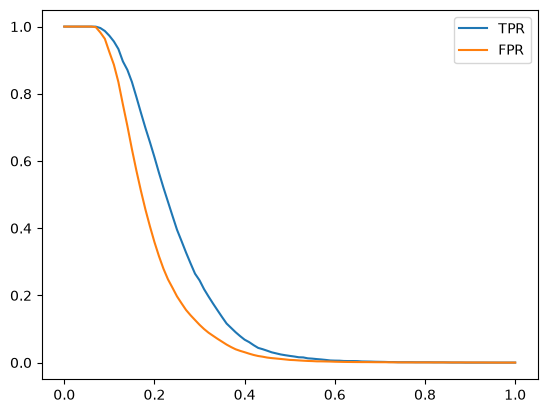

In [ ]:
scores = []

thresholds = np.linspace(0, 1, 101)

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()
    
    scores.append((t, tp, fp, fn, tn))

columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
df_scores = pd.DataFrame(scores, columns=columns)

df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn)
df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn)

plt.plot(df_scores.threshold, df_scores['tpr'], label='TPR')
plt.plot(df_scores.threshold, df_scores['fpr'], label='FPR')
plt.legend()

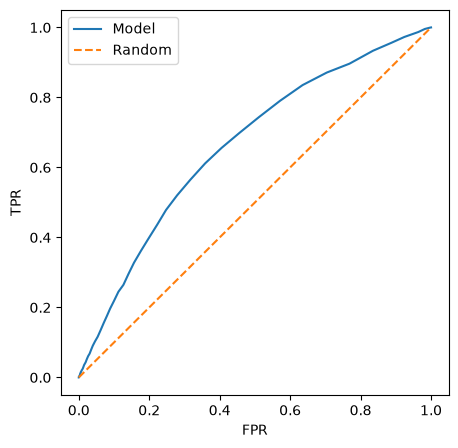

In [ ]:
plt.figure(figsize=(5, 5))

plt.plot(df_scores.fpr, df_scores.tpr, label='Model')
plt.plot([0, 1], [0, 1], label='Random', linestyle='--')

plt.xlabel('FPR')
plt.ylabel('TPR')

plt.legend()

### AUC

In [ ]:
from sklearn.metrics import roc_auc_score

roc_auc_score(y_val, y_pred)

0.6625047379697826

The area under the curve is 0.66, which we can state is relatively poor. The model clearly needs to be trained. 

### parameter tuning


In [ ]:
def train(df_train, y_train, C=1.0):
    dicts = df_train[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(C=C, max_iter=1000)
    model.fit(X_train, y_train)
    
    return dv, model

def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [ ]:
from sklearn.model_selection import KFold

kfold = KFold(n_splits=5, shuffle=True, random_state=1)

In [ ]:
from tqdm.auto import tqdm

n_splits = 5

for C in tqdm([0.001, 0.01, 0.1, 0.5, 1, 5, 10]):
    kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.no_show_int.values
        y_val = df_val.no_show_int.values

        dv, model = train(df_train, y_train, C=C)
        y_pred = predict(df_val, dv, model)

        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

    print('C=%s %.3f +- %.3f' % (C, np.mean(scores), np.std(scores)))

  0%|          | 0/7 [00:00<?, ?it/s]

C=0.001 0.670 +- 0.005
C=0.01 0.668 +- 0.006
C=0.1 0.666 +- 0.005
C=0.5 0.666 +- 0.005
C=1 0.665 +- 0.005
C=5 0.665 +- 0.005
C=10 0.665 +- 0.005


No strong sensitivity to C here, the models get slightly worse with a higher C. 
recomendation is thus to set the C to 0.001

Final logistic model is thus:

In [ ]:
dv, model = train(df_full_train, df_full_train.no_show_int.values, C=0.001)
y_pred = predict(df_test, dv, model)

auc = roc_auc_score(y_test, y_pred)
auc

0.6731606269055441

## Descision tree-based model

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import roc_auc_score
from sklearn.tree import export_text

dicts_train = df_train[categorical + numerical].to_dict(orient="records")
dicts_val = df_val[categorical + numerical].to_dict(orient="records")

dv = DictVectorizer(sparse=False)

X_train = dv.fit_transform(dicts_train)
X_val = dv.transform(dicts_val)


dt = DecisionTreeClassifier(
    max_depth=3, # without a max dept the AUC was 0.571 for validation and 0.996 for training data so it was overfitting. 
)

dt.fit(X_train, y_train)

y_pred = dt.predict_proba(X_train)[:, 1]
auc = roc_auc_score(y_train, y_pred)
print('train:', auc)

y_pred = dt.predict_proba(X_val)[:, 1]
auc = roc_auc_score(y_val, y_pred)
print('val:', auc)


train: 0.7174119416650904
val: 0.7167334544686883


training and validation AUC are almost equal, the model is generalizable over the split dataset. 

In [ ]:
# uncomment if you would like to see the decision tree
# print(export_text(dt, feature_names=list(dv.get_feature_names_out())))


### parameter tuning


#### Tune max_depth

In [ ]:
# same is in the course we start with adjusting the max_depth
for depth in [1, 2, 3, 4, 5, 6, 10, 15, 20, None]:

    dt = DecisionTreeClassifier(
        max_depth=depth
    )

    dt.fit(X_train, y_train)

    y_pred = dt.predict_proba(X_val)[:, 1]

    auc = roc_auc_score(y_val, y_pred)

    print(depth, round(auc, 3))

1 0.666
2 0.703
3 0.717
4 0.723
5 0.725
6 0.725
10 0.719
15 0.704
20 0.682
None 0.574


Depths 4, 5, and 6 give the best results with a AUC of about 0.725

#### Tune min_samples_leaf

In [ ]:
scores = []

for depth in [4, 5, 6]:
    for leaf_size in [1, 5, 10, 15, 20, 50, 100]:

        dt = DecisionTreeClassifier(
            max_depth=depth,
            min_samples_leaf=leaf_size,
            random_state=1
        )

        dt.fit(X_train, y_train)

        y_pred = dt.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)

        scores.append((depth, leaf_size, auc))


columns = ['max_depth', 'min_samples_leaf', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)

df_scores_pivot = df_scores.pivot(index='min_samples_leaf', columns=['max_depth'], values=['auc'])
df_scores_pivot.round(3)

auc              
max_depth             4      5      6
min_samples_leaf                     
1                 0.723  0.725  0.725
5                 0.723  0.725  0.726
10                0.723  0.725  0.725
15                0.723  0.725  0.725
20                0.723  0.725  0.724
50                0.723  0.725  0.724
100               0.723  0.724  0.724

AUC valuees are almost equal regardless of min_samples_leaf.
depths 4 and 5 see no difference in AUC uppon changing the min_samples_leaf.
depth 6 is slightly better for min_samples_leaf = 5 

Lets check if anything interesting happens if we do this again for all depths.

In [ ]:
scores = []

for depth in [1, 2, 3, 4, 5, 6, 10, 15, 20, None]:
    for leaf_size in [1, 5, 10, 15, 20, 50, 100]:

        dt = DecisionTreeClassifier(
            max_depth=depth,
            min_samples_leaf=leaf_size,
            random_state=1
        )

        dt.fit(X_train, y_train)

        y_pred = dt.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)

        scores.append((depth, leaf_size, auc))


columns = ['max_depth', 'min_samples_leaf', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)

df_scores_pivot = df_scores.pivot(index='min_samples_leaf', columns=['max_depth'], values=['auc'])
df_scores_pivot.round(3)

auc                                                   \
max_depth           NaN   1.0    2.0    3.0    4.0    5.0    6.0    10.0   
min_samples_leaf                                                           
1                 0.575  0.666  0.703  0.717  0.723  0.725  0.725  0.718   
5                 0.655  0.666  0.703  0.717  0.723  0.725  0.726  0.723   
10                0.688  0.666  0.703  0.717  0.723  0.725  0.725  0.723   
15                0.701  0.666  0.703  0.717  0.723  0.725  0.725  0.727   
20                0.704  0.666  0.703  0.717  0.723  0.725  0.724  0.725   
50                0.712  0.666  0.703  0.717  0.723  0.725  0.724  0.722   
100               0.720  0.666  0.703  0.717  0.723  0.724  0.724  0.726   

                                
max_depth          15.0   20.0  
min_samples_leaf                
1                 0.707  0.683  
5                 0.711  0.698  
10                0.717  0.708  
15                0.719  0.714  
20                0.716  0.711  
50                0.716  0.713  
100               0.721  0.720

No additional combinations stand out as improvements, however interestingly depth = 10 with min_samples_leaf = 100 performs equally to depth = 6 + min_samples_leaf = 5

Next lets check out the tree with the tuned parameters

In [ ]:
dt = DecisionTreeClassifier(max_depth=6, min_samples_leaf=5)
dt.fit(X_train, y_train)

# print(export_text(dt, feature_names=list(dv.get_feature_names_out())))

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",6
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples 

## Random forest-based model

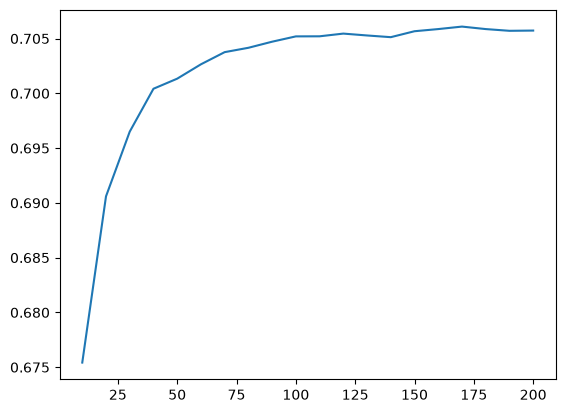

In [ ]:
from sklearn.ensemble import RandomForestClassifier

scores = []

for n in range(10, 201, 10):
    rf = RandomForestClassifier(n_estimators=n, random_state=1)
    rf.fit(X_train, y_train)

    y_pred = rf.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, y_pred)

    scores.append((n, auc))

df_scores = pd.DataFrame(scores, columns=['n_estimators', 'auc'])
plt.plot(df_scores.n_estimators, df_scores.auc)

Adding more than a 100 trees does little to the improve the AUC of the model

#### Tuning max_depth

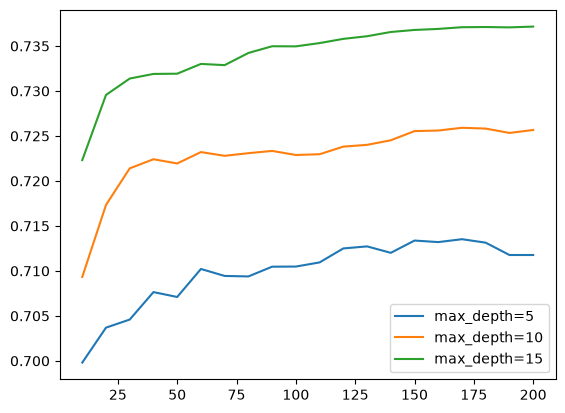

In [ ]:
scores = []

for d in [5, 10, 15]:
    for n in range(10, 201, 10):
        rf = RandomForestClassifier(n_estimators=n,
                                    max_depth=d,
                                    random_state=1)
        rf.fit(X_train, y_train)

        y_pred = rf.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)

        scores.append((d, n, auc))


columns = ['max_depth', 'n_estimators', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)

for d in [5, 10, 15]:
    df_subset = df_scores[df_scores.max_depth == d]

    plt.plot(df_subset.n_estimators, df_subset.auc,
             label='max_depth=%d' % d)

plt.legend()

Higher depth gives a decent improvement, as higher depth might improve even more so we will do this again with 15, 20 and 25

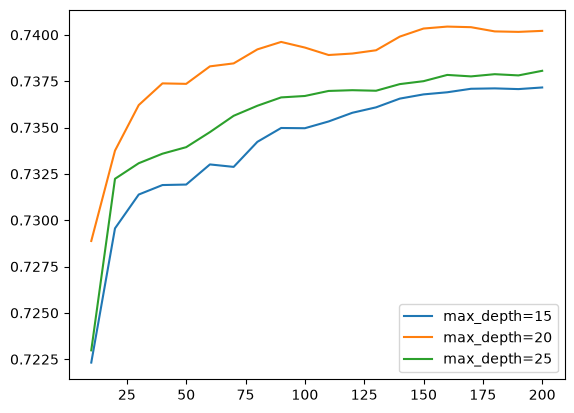

In [ ]:
scores = []

for d in [15, 20, 25]:
    for n in range(10, 201, 10):
        rf = RandomForestClassifier(n_estimators=n,
                                    max_depth=d,
                                    random_state=1)
        rf.fit(X_train, y_train)

        y_pred = rf.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)

        scores.append((d, n, auc))


columns = ['max_depth', 'n_estimators', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)

for d in [15, 20, 25]:
    df_subset = df_scores[df_scores.max_depth == d]

    plt.plot(df_subset.n_estimators, df_subset.auc,
             label='max_depth=%d' % d)

plt.legend()

A depth of 20 gives our best results, it starts to deteriorate at 25. 

In [ ]:
max_depth = 20

#### Tuning min_samples_leaf

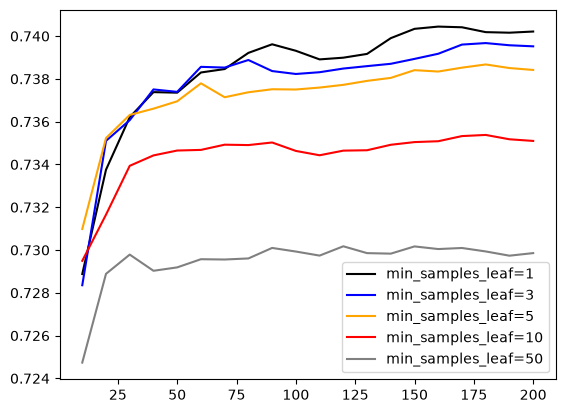

In [ ]:
scores = []

for s in [1, 3, 5, 10, 50]:
    for n in range(10, 201, 10):
        rf = RandomForestClassifier(n_estimators=n,
                                    max_depth=max_depth,
                                    min_samples_leaf=s,
                                    random_state=1)
        rf.fit(X_train, y_train)

        y_pred = rf.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)

        scores.append((s, n, auc))

columns = ['min_samples_leaf', 'n_estimators', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)

colors = ['black', 'blue', 'orange', 'red', 'grey']
values = [1, 3, 5, 10, 50]

for s, col in zip(values, colors):
    df_subset = df_scores[df_scores.min_samples_leaf == s]

    plt.plot(df_subset.n_estimators, df_subset.auc,
             color=col,
             label='min_samples_leaf=%d' % s)

plt.legend()

Curves 1 to 5 are close together but diverge after a n_estimators of 75. 
we will pick a leaf of 1 as it is slightly higher.

In [ ]:
scores = []

for s in [1, 2, 3, 4, 5]:
    for n in range(10, 500, 10):
        rf = RandomForestClassifier(n_estimators=n,
                                    max_depth=max_depth,
                                    min_samples_leaf=s,
                                    random_state=1)
        rf.fit(X_train, y_train)

        y_pred = rf.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)

        scores.append((s, n, auc))

columns = ['min_samples_leaf', 'n_estimators', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)

colors = ['black', 'blue', 'orange', 'red', 'grey']
values = [1, 2, 3, 4, 5]

for s, col in zip(values, colors):
    df_subset = df_scores[df_scores.min_samples_leaf == s]

    plt.plot(df_subset.n_estimators, df_subset.auc,
             color=col,
             label='min_samples_leaf=%d' % s)

plt.legend()

Curves ....

In [ ]:
rf = RandomForestClassifier(n_estimators=200,
                            max_depth=max_depth,
                            min_samples_leaf=1,
                            random_state=1)
rf.fit(X_train, y_train)

## Export model training logic to script